<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis

### Objectives:
1. Load/generate medical data (Haemoglobin, RBC Count, Glucose, Cholesterol, BMI) and standardise features.
2. Compute covariance and correlation matrices and plot them as heatmaps.
3. Compute eigenvalues and eigenvectors with NumPy, and sort them.
4. Plot the data in 2D with the top two eigenvectors drawn as arrows.
5. Report the percentage of variance captured by each eigenvalue.
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

# Task 1: Generate synthetic patient records (n=200)
# To make them correlated, we start from a multivariate normal distribution
mean = [14, 4.5, 100, 200, 25]  # Hb, RBC, Glucose, Chol, BMI
cov_matrix = [
    [2.0,  0.6,   2.0,   1.5,   0.5],
    [0.6,  0.5,   0.5,   0.2,   0.1],
    [2.0,  0.5, 200.0,  25.0,  15.0],
    [1.5,  0.2,  25.0, 900.0,  30.0],
    [0.5,  0.1,  15.0,  30.0,  16.0]
]

data = np.random.multivariate_normal(mean, cov_matrix, size=200)
columns = ['Haemoglobin', 'RBC_Count', 'Glucose', 'Cholesterol', 'BMI']
df = pd.DataFrame(data, columns=columns)

# Standardise the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_data, columns=columns)

print("First 5 rows of standardised dataset:")
display(df_scaled.head())

First 5 rows of standardised dataset:


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
0,-1.414976,-1.187413,0.064450,-0.552469,0.555814
1,0.387462,0.646010,-1.607336,0.263426,0.369977
2,2.355031,0.123094,0.472997,0.471046,0.474357
3,1.346951,-0.312767,1.029404,0.565933,0.739402
4,1.584757,0.585142,0.086241,-1.589587,-0.295686


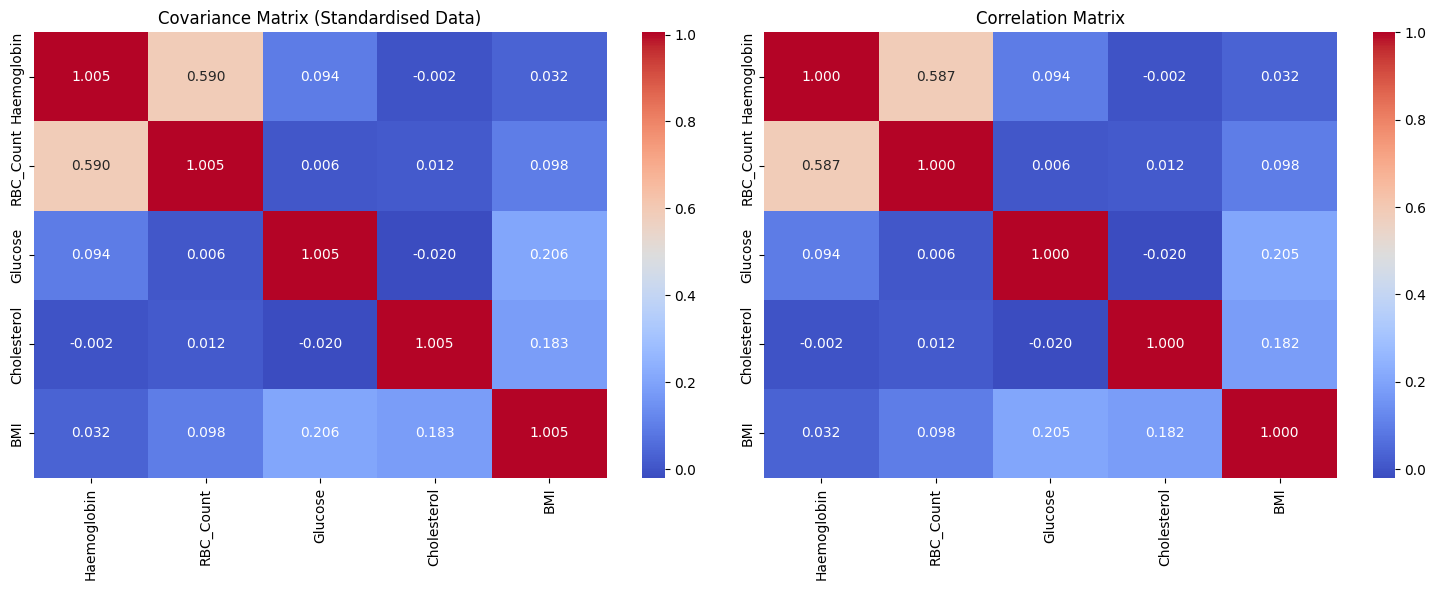

In [2]:
# Task 2: Compute covariance and correlation matrices
cov_mat = df_scaled.cov()
corr_mat = df_scaled.corr()

# Plot them as heatmaps side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cov_mat, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0])
axes[0].set_title('Covariance Matrix (Standardised Data)')

sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[1])
axes[1].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()

In [3]:
# Task 3: Compute eigenvalues and eigenvectors using NumPy
eigenvalues, eigenvectors = np.linalg.eig(cov_mat.values)

# Sort by eigenvalue in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

for i in range(len(eigenvalues)):
    print(f"Principal Component {i+1}:")
    print(f"  Eigenvalue: {eigenvalues[i]:.4f}")
    print(f"  Eigenvector (weights): {eigenvectors[:, i]}\n")

Principal Component 1:
  Eigenvalue: 1.6303
  Eigenvector (weights): [0.67641555 0.67621743 0.17917167 0.06876628 0.21991068]

Principal Component 2:
  Eigenvalue: 1.2394
  Eigenvector (weights): [ 0.2043606   0.19158112 -0.47114065 -0.48311365 -0.68275992]

Principal Component 3:
  Eigenvalue: 1.0261
  Eigenvector (weights): [-0.00279677  0.11273381 -0.68814578  0.71675405 -0.00151458]

Principal Component 4:
  Eigenvalue: 0.7301
  Eigenvector (weights): [ 0.15037228 -0.11133624  0.50057068  0.49724491 -0.68349756]

Principal Component 5:
  Eigenvalue: 0.3991
  Eigenvector (weights): [ 0.69143264 -0.6934854  -0.14767665 -0.02972443  0.13530324]



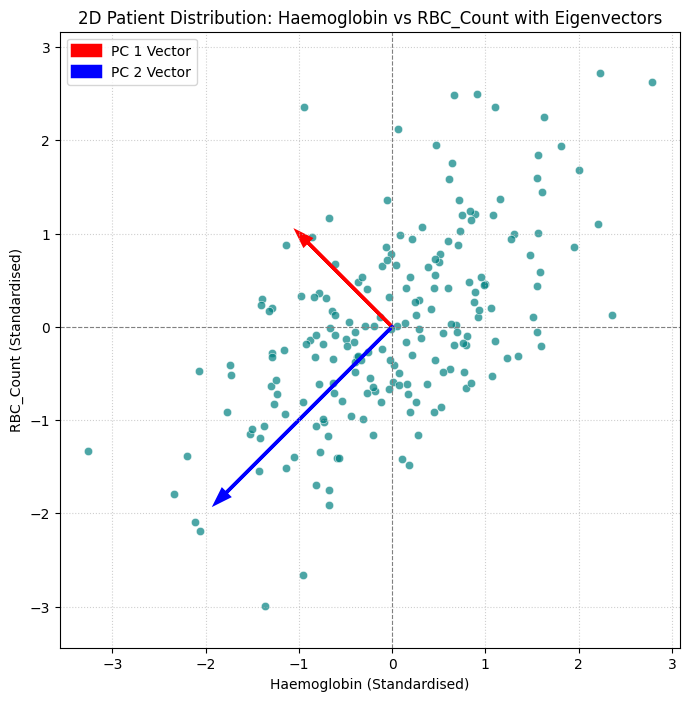

In [4]:
# Task 4: Plot 2D projection of top two features and draw top eigenvectors
# Let's select two highly correlated features for clear 2D visualization (e.g., Haemoglobin vs RBC Count)
feat1, feat2 = 'Haemoglobin', 'RBC_Count'
idx1, idx2 = columns.index(feat1), columns.index(feat2)

# Extract 2D sub-covariance
cov_2d = df_scaled[[feat1, feat2]].cov()
eigvals_2d, eigvecs_2d = np.linalg.eig(cov_2d)

# Plot the standardised patient data
plt.figure(figsize=(8, 8))
snk = sns.scatterplot(data=df_scaled, x=feat1, y=feat2, alpha=0.7, color='teal')

# Scale eigenvectors for visibility as arrows
scale_factor = 2.0
for i in range(2):
    arrow = eigvecs_2d[:, i] * np.sqrt(eigvals_2d[i]) * scale_factor
    plt.arrow(0, 0, arrow[0], arrow[1], head_width=0.1, head_length=0.15,
              fc='red' if i==0 else 'blue', ec='red' if i==0 else 'blue',
              linewidth=2.5, label=f'PC {i+1} Vector' if i<2 else "")

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title(f'2D Patient Distribution: {feat1} vs {feat2} with Eigenvectors')
plt.xlabel(f'{feat1} (Standardised)')
plt.ylabel(f'{feat2} (Standardised)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.axis('equal')
plt.show()

Variance Explanation Report:
--------------------------------------------------
PC 1: Eigenval = 1.6303 | Explained Var = 32.44% | Cumulative Var = 32.44%
PC 2: Eigenval = 1.2394 | Explained Var = 24.66% | Cumulative Var = 57.11%
PC 3: Eigenval = 1.0261 | Explained Var = 20.42% | Cumulative Var = 77.53%
PC 4: Eigenval = 0.7301 | Explained Var = 14.53% | Cumulative Var = 92.06%
PC 5: Eigenval = 0.3991 | Explained Var = 7.94% | Cumulative Var = 100.00%


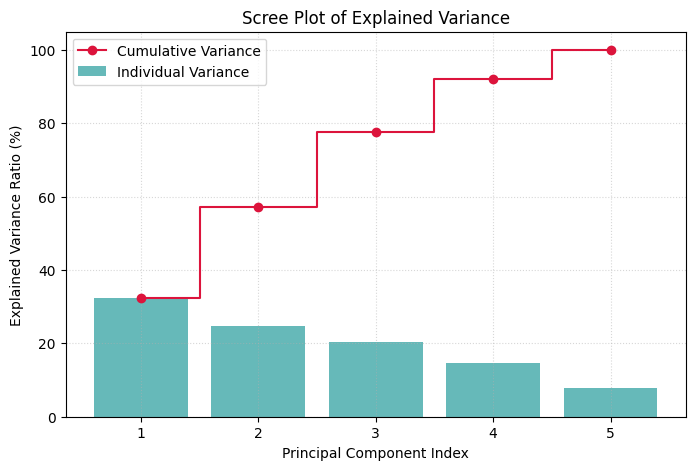

In [5]:
# Task 5: Report percentage of variance captured by each eigenvalue
total_variance = np.sum(eigenvalues)
explained_variance_ratio = (eigenvalues / total_variance) * 100
cumulative_variance = np.cumsum(explained_variance_ratio)

# Print report
print("Variance Explanation Report:")
print("--------------------------------------------------")
for i, (val, ratio) in enumerate(zip(eigenvalues, explained_variance_ratio)):
    print(f"PC {i+1}: Eigenval = {val:.4f} | Explained Var = {ratio:.2f}% | Cumulative Var = {cumulative_variance[i]:.2f}%")

# Visualise scree plot
plt.figure(figsize=(8, 5))
plt.bar(range(1, 6), explained_variance_ratio, alpha=0.6, align='center', label='Individual Variance', color='darkcyan')
plt.step(range(1, 6), cumulative_variance, where='mid', label='Cumulative Variance', color='crimson', marker='o')
plt.ylabel('Explained Variance Ratio (%)')
plt.xlabel('Principal Component Index')
plt.title('Scree Plot of Explained Variance')
plt.xticks(range(1, 6))
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()